In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from sklearn import metrics
import seaborn as sn

In [2]:
col_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

data = pd.read_csv('diabetes.csv', header=None, names=col_names)

print(data.shape)
data.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [4]:
feature_cols = ['Pregnancies', 'Insulin', 'BMI', 'Age', 'Glucose', 'BloodPressure', 'DiabetesPedigreeFunction']

x = data[feature_cols]
y = data.Outcome

In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=5)

print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(537, 7) (537,) (231, 7) (231,)


In [6]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [7]:
model = SVC(kernel='rbf', random_state=0)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

SVC [kernel - rbf]
[[135  25]
 [ 22  49]]
Accuracy: 0.7965367965367965
Accuracy in Percentage: 79 %
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       157
           1       0.69      0.66      0.68        74

    accuracy                           0.80       231
   macro avg       0.77      0.76      0.76       231
weighted avg       0.79      0.80      0.80       231



[Text(0.5, 1.0, 'SVC [rbf]')]

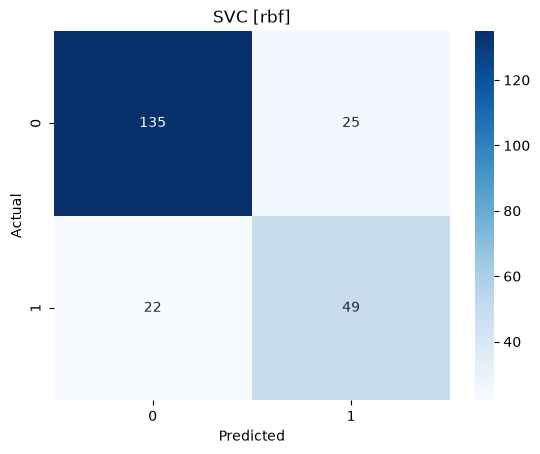

In [8]:
conf_matrix = metrics.confusion_matrix(y_test, y_pred)
print('SVC [kernel - rbf]')
print(conf_matrix)

accuracy_score = metrics.accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy_score)
print("Accuracy in Percentage:", int(accuracy_score*100), "%")
print(classification_report(y_pred, y_test))

conf_mat = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
sn.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues').set(title='SVC [rbf]')

In [9]:
model = SVC(kernel='linear', random_state=0)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

SVC [kernel - linear]
[[136  24]
 [ 23  48]]
Accuracy: 0.7965367965367965
Accuracy in Percentage: 79 %


              precision    recall  f1-score   support

           0       0.85      0.86      0.85       159
           1       0.68      0.67      0.67        72

    accuracy                           0.80       231
   macro avg       0.76      0.76      0.76       231
weighted avg       0.80      0.80      0.80       231



[Text(0.5, 1.0, 'SVC [linear]')]

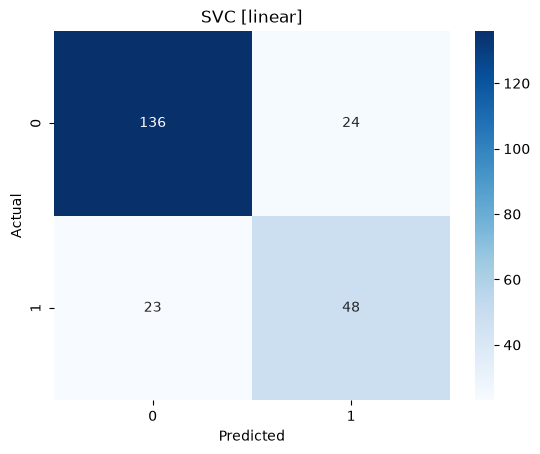

In [10]:
conf_matrix = metrics.confusion_matrix(y_test, y_pred)
print('SVC [kernel - linear]')
print(conf_matrix)

accuracy_score = metrics.accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy_score)
print("Accuracy in Percentage:", int(accuracy_score*100), "%")
print(classification_report(y_pred, y_test))

conf_mat = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
sn.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues').set(title='SVC [linear]')